# Marco 1 — Algoritmo Genético para o TSP das 27 Capitais Brasileiras

**Componente Curricular:** Tópicos Avançados em Computação I — IFPA Campus Ananindeua  
**Professor:** Fabio Ferreira  
**Equipe:**
- Ederson Costa Moreira Filho
- Ilard Moisés da Silva Lamarão
- João Vitor de Almeida Miranda

---

**Problema:** encontrar o menor circuito fechado que visite as 26 capitais estaduais + Brasília (N = 27) exatamente uma vez e volte à origem.

**Espaço de busca:** (27 − 1)! / 2 ≈ 2,01 × 10²⁶ rotas — inviável por força bruta. Por isso usamos uma metaheurística: um **Algoritmo Genético** implementado com a biblioteca **DEAP**.

## 0. Importações e dados das capitais

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from math import radians, cos, sin, asin, sqrt

try:
    from deap import base, creator, tools, algorithms
except ImportError:
    import subprocess
    import sys
    print("Instalando biblioteca DEAP...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "deap"])
    from deap import base, creator, tools, algorithms

# ------------------------------------------------------------------------------
#  DICIONÁRIO DE DADOS: 27 CAPITAIS BRASILEIRAS (Latitude, Longitude)
# ------------------------------------------------------------------------------
CAPITAIS_BRASIL = {
    "Rio Branco (AC)": (-9.97499, -67.8076),
    "Maceió (AL)": (-9.66583, -35.7353),
    "Macapá (AP)": (0.034934, -51.0694),
    "Manaus (AM)": (-3.10194, -60.0250),
    "Salvador (BA)": (-12.9711, -38.5108),
    "Fortaleza (CE)": (-3.71722, -38.5433),
    "Brasília (DF)": (-15.7801, -47.9292),
    "Vitória (ES)": (-20.3194, -40.3378),
    "Goiânia (GO)": (-16.6864, -49.2643),
    "São Luís (MA)": (-2.53073, -44.3068),
    "Cuiabá (MT)": (-15.6010, -56.0979),
    "Campo Grande (MS)": (-20.4428, -54.6464),
    "Belo Horizonte (MG)": (-19.9208, -43.9378),
    "Belém (PA)": (-1.45575, -48.4902),
    "João Pessoa (PB)": (-7.11532, -34.8610),
    "Curitiba (PR)": (-25.4284, -49.2733),
    "Recife (PE)": (-8.05428, -34.8813),
    "Teresina (PI)": (-5.08921, -42.8016),
    "Rio de Janeiro (RJ)": (-22.9068, -43.1729),
    "Natal (RN)": (-5.79448, -35.2110),
    "Porto Alegre (RS)": (-30.0346, -51.2177),
    "Porto Velho (RO)": (-8.76194, -63.9039),
    "Boa Vista (RR)": (2.82384, -60.6758),
    "Florianópolis (SC)": (-27.5954, -48.5480),
    "São Paulo (SP)": (-23.5505, -46.6333),
    "Aracaju (SE)": (-10.9111, -37.0717),
    "Palmas (TO)": (-10.1844, -48.3336)
}

NOMES_CIDADES = list(CAPITAIS_BRASIL.keys())
N_CIDADES = len(NOMES_CIDADES)

print(f"Mapeamento concluído: {N_CIDADES} capitais carregadas.")
print(f"Espaço de Busca Total: {N_CIDADES - 1}! / 2 ≈ 2.01e26 rotas distintas.\n")

Mapeamento concluído: 27 capitais carregadas.
Espaço de Busca Total: 26! / 2 ≈ 2.01e26 rotas distintas.



## TODO 1 — Matriz de distâncias (Haversine)

A distância entre duas capitais é a distância de grande círculo (Haversine), em km, com raio da Terra R = 6371 km. Preenchemos uma matriz simétrica 27 × 27 com diagonal zero, para que a fitness consulte as distâncias em O(1).

In [2]:
def haversine(lat1, lon1, lat2, lon2):
    """Calcula a distância em km entre dois pontos geográficos."""
    R = 6371.0  # Raio da Terra em km
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * asin(sqrt(a))
    return R * c

MATRIZ_DISTANCIAS = np.zeros((N_CIDADES, N_CIDADES))

# TODO 1.1: Preenche a matriz 27 x 27 com a distância de Haversine entre cada par (i, j).
# A diagonal (i == j) permanece 0 km.
for i in range(N_CIDADES):
    for j in range(N_CIDADES):
        if i != j:
            c1_coords = CAPITAIS_BRASIL[NOMES_CIDADES[i]]
            c2_coords = CAPITAIS_BRASIL[NOMES_CIDADES[j]]
            MATRIZ_DISTANCIAS[i][j] = haversine(c1_coords[0], c1_coords[1],
                                                c2_coords[0], c2_coords[1])

print("Matriz de distâncias inicializada.")

Matriz de distâncias inicializada.


In [3]:
# Conferência rápida da matriz
print("Dimensão:", MATRIZ_DISTANCIAS.shape)
print("Simétrica:", np.allclose(MATRIZ_DISTANCIAS, MATRIZ_DISTANCIAS.T))
print("Diagonal zerada:", np.all(np.diag(MATRIZ_DISTANCIAS) == 0))
b, s = NOMES_CIDADES.index("Belém (PA)"), NOMES_CIDADES.index("São Paulo (SP)")
print(f"Exemplo — Belém → São Paulo: {MATRIZ_DISTANCIAS[b][s]:.1f} km")

Dimensão: (27, 27)
Simétrica: True
Diagonal zerada: True
Exemplo — Belém → São Paulo: 2465.0 km


## TODO 2 — Função de fitness (circuito fechado)

A aptidão de um indivíduo é o comprimento total da rota em km. O índice `(k + 1) % n` garante o trecho de retorno da última cidade para a primeira. Como queremos **minimizar**, a fitness é usada com peso −1.0 no DEAP. A função retorna uma **tupla**, como o DEAP exige.

In [4]:
def avaliar_rota(individual):
    """
    Recebe um indivíduo (lista com permutação dos índices 0 a 26 das cidades).
    Retorna uma TUPLA (distancia_total,) contendo a soma das distâncias do circuito FECHADO
    (incluindo o retorno da última cidade para a cidade inicial).
    """
    distancia_total = 0.0

    # TODO 2.1: soma das distâncias entre cidades consecutivas.
    # O módulo (k + 1) % n faz a última cidade voltar para a primeira (fecha o ciclo).
    n = len(individual)
    for k in range(n):
        origem = individual[k]
        destino = individual[(k + 1) % n]
        distancia_total += MATRIZ_DISTANCIAS[origem][destino]

    # O DEAP exige que a avaliação retorne uma TUPLA
    return (distancia_total,)

In [5]:
# Teste: a rota na ordem do dicionário (0, 1, ..., 26) e uma rota aleatória
print(f"Rota sequencial: {avaliar_rota(list(range(N_CIDADES)))[0]:,.1f} km")
random.seed(0)
print(f"Rota aleatória:  {avaliar_rota(random.sample(range(N_CIDADES), N_CIDADES))[0]:,.1f} km")

Rota sequencial: 49,352.0 km
Rota aleatória:  52,041.4 km


## TODO 3 — Configuração do DEAP

| Componente | Escolha | Motivo |
|---|---|---|
| Fitness | `FitnessMin`, `weights=(-1.0,)` | Menor distância = indivíduo mais apto |
| Indivíduo | `list` de 27 inteiros | Cada gene é uma cidade; o cromossomo é a ordem de visita |
| Inicialização | `random.sample(range(27), 27)` | Gera permutações válidas, sem cidade repetida |
| Crossover | `cxOrdered` (OX) | Preserva um trecho do pai 1 e completa na ordem do pai 2, sem duplicar cidades |
| Mutação | `mutShuffleIndexes`, `indpb=0.05` | Troca posições de cidades, mantendo a permutação válida |
| Seleção | `selTournament`, `tournsize=3` | Pressão seletiva moderada, preservando diversidade |

O crossover de ponto de corte tradicional quebraria o TSP: geraria filhos com cidades repetidas e outras faltando. Por isso usamos operadores de **permutação**.

In [6]:
# Limpeza de execuções anteriores no Colab
if "FitnessMin" in creator.__dict__:
    del creator.FitnessMin
if "Individual" in creator.__dict__:
    del creator.Individual

# TODO 3.1: Fitness de MINIMIZAÇÃO (peso negativo -> menor distância é melhor)
creator.create("FitnessMin", base.Fitness, weights=(-1.0,))

# TODO 3.2: Indivíduo = lista de inteiros com o atributo .fitness
creator.create("Individual", list, fitness=creator.FitnessMin)

toolbox = base.Toolbox()

# TODO 3.3: Gerador de permutação sem repetição dos índices 0..26
toolbox.register("indices", random.sample, range(N_CIDADES), N_CIDADES)
toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.indices)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# TODO 3.4: Avaliação e operadores genéticos adequados para PERMUTAÇÃO
toolbox.register("evaluate", avaliar_rota)
toolbox.register("mate", tools.cxOrdered)                          # Ordered Crossover (OX): não duplica cidades
toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.05)    # Troca posições sem duplicar cidades
toolbox.register("select", tools.selTournament, tournsize=3)       # Seleção por torneio de 3

## TODO 4 — Loop evolutivo (`eaSimple`)

Hiperparâmetros: população de **200**, crossover **0,85**, mutação **0,20**, **300 gerações**, semente **42** (reprodutibilidade).  
O `HallOfFame(1)` guarda a melhor rota já encontrada e o `Statistics` registra a distância mínima e a média de cada geração no `logbook`.

In [7]:
def executar_ag(semente=42, verbose=True):
    random.seed(semente)
    np.random.seed(semente)

    # TODO 4.1: Hiperparâmetros do AG
    TAMANHO_POPULACAO = 200
    PROB_CROSSOVER = 0.85
    PROB_MUTACAO = 0.20
    NUM_GERACOES = 300

    # TODO 4.2: População inicial (200 rotas aleatórias)
    pop = toolbox.population(n=TAMANHO_POPULACAO)

    # TODO 4.3: HallOfFame guarda a melhor rota já vista; Statistics registra min e média
    hof = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats.register("min", np.min)
    stats.register("avg", np.mean)

    # TODO 4.4: Loop evolutivo
    pop, logbook = algorithms.eaSimple(
        pop, toolbox,
        cxpb=PROB_CROSSOVER,
        mutpb=PROB_MUTACAO,
        ngen=NUM_GERACOES,
        stats=stats,
        halloffame=hof,
        verbose=verbose
    )

    melhor_rota = hof[0]
    melhor_distancia = melhor_rota.fitness.values[0]

    return pop, logbook, melhor_rota, melhor_distancia

In [8]:
%%time
pop, logbook, melhor_rota, melhor_dist = executar_ag(semente=42, verbose=True)

gen	nevals	min    	avg    
0  	200   	37415.9	48282.6
1  	176   	35828.7	45780  
2  	165   	35218.7	43375  
3  	172   	32270.1	41889.4
4  	184   	32427.8	40986.2
5  	179   	32427.8	40376.3
6  	166   	32116.9	39212.5
7  	172   	29834.7	38911.3
8  	186   	29834.7	38352.1
9  	165   	29961  	37590.4
10 	177   	27587.4	36969.7
11 	169   	28239  	36328.8
12 	170   	27992.9	35688.7


13 	174   	27889.5	35217.8
14 	186   	28801.7	34639.4


15 	182   	26412  	34890.5
16 	185   	27114  	34545.1
17 	190   	25895.8	34400.3
18 	167   	25895.8	33925.1
19 	169   	23687.1	33460.1


20 	174   	23687.1	32951.2
21 	185   	23458.4	33023  


22 	174   	24209.9	32230.8
23 	171   	24229  	32234.8
24 	170   	24171  	31482.7
25 	176   	23808.3	31205.5
26 	182   	23534.6	31367  
27 	176   	22111.2	31095.7
28 	165   	21700.5	30247.7
29 	180   	21700.5	29636.9
30 	171   	20115.1	29162.7
31 	174   	21371.4	28671.7
32 	179   	20841.1	27748.1
33 	179   	20841.1	28283.4
34 	173   	20841.1	27693.7
35 	174   	21239.8	27579.4


36 	178   	20709.3	27234.5
37 	178   	20659.5	26704.4
38 	185   	20791.2	26441.8
39 	179   	20767.4	26104.5
40 	181   	19873.8	25542  
41 	175   	19723.7	25114  
42 	178   	18346.9	24435.8


... (30 outputs left out)

277	171   	13892  	14914.4
278	171   	13892  	15100.8
279	179   	13892  	14770.9
280	181   	13892  	15156.1
281	172   	13892  	15259.8
282	182   	13892  	14869.2
283	173   	13892  	14943.2
284	170   	13892  	14735.4


285	191   	13892  	15392.4
286	176   	13892  	14899  
287	179   	13892  	15144.8
288	186   	13892  	15129.3
289	175   	13892  	14942.4
290	170   	13892  	15129.1


291	181   	13892  	15272.6
292	170   	13892  	15350.9
293	168   	13892  	14743.7
294	172   	13892  	15233.3
295	179   	13892  	14867.3
296	177   	13892  	14967.7
297	180   	13892  	15646.8
298	166   	13892  	15532.3
299	185   	13892  	15510.7


300	174   	13892  	15368  
CPU times: user 2.29 s, sys: 58.4 ms, total: 2.35 s
Wall time: 2.37 s


In [9]:
def imprimir_rota(melhor_rota, melhor_distancia):
    """Lista a sequência de capitais com a distância de cada trecho."""
    print(f"\nMELHOR ROTA ENCONTRADA — {melhor_distancia:,.2f} km\n".replace(",", "X").replace(".", ",").replace("X", "."))
    n = len(melhor_rota)
    for k in range(n):
        a, b = melhor_rota[k], melhor_rota[(k + 1) % n]
        print(f"{k + 1:2d}. {NOMES_CIDADES[a]:<22} -> {NOMES_CIDADES[b]:<22} {MATRIZ_DISTANCIAS[a][b]:8.1f} km")


imprimir_rota(melhor_rota, melhor_dist)

# Validação: a rota é uma permutação válida (27 cidades, nenhuma repetida)
assert sorted(melhor_rota) == list(range(N_CIDADES))
print("\nRota válida: todas as 27 capitais visitadas exatamente uma vez.")


MELHOR ROTA ENCONTRADA — 13.891,99 km

 1. Porto Alegre (RS)      -> Curitiba (PR)             546.7 km
 2. Curitiba (PR)          -> Campo Grande (MS)         780.9 km
 3. Campo Grande (MS)      -> Cuiabá (MT)               559.8 km
 4. Cuiabá (MT)            -> Rio Branco (AC)          1414.9 km
 5. Rio Branco (AC)        -> Porto Velho (RO)          449.0 km
 6. Porto Velho (RO)       -> Manaus (AM)               761.6 km
 7. Manaus (AM)            -> Boa Vista (RR)            662.9 km
 8. Boa Vista (RR)         -> Macapá (AP)              1111.9 km
 9. Macapá (AP)            -> Belém (PA)                331.2 km
10. Belém (PA)             -> São Luís (MA)             480.0 km
11. São Luís (MA)          -> Teresina (PI)             329.9 km
12. Teresina (PI)          -> Fortaleza (CE)            496.1 km
13. Fortaleza (CE)         -> Natal (RN)                435.5 km
14. Natal (RN)             -> João Pessoa (PB)          151.9 km
15. João Pessoa (PB)       -> Recife (PE)         

## TODO 5 — Visualização: curva de convergência e mapa da rota

- **Esquerda:** distância mínima (melhor indivíduo) e média da população por geração.
- **Direita:** capitais plotadas por longitude × latitude, conectadas na ordem da melhor rota (a estrela marca a cidade inicial).

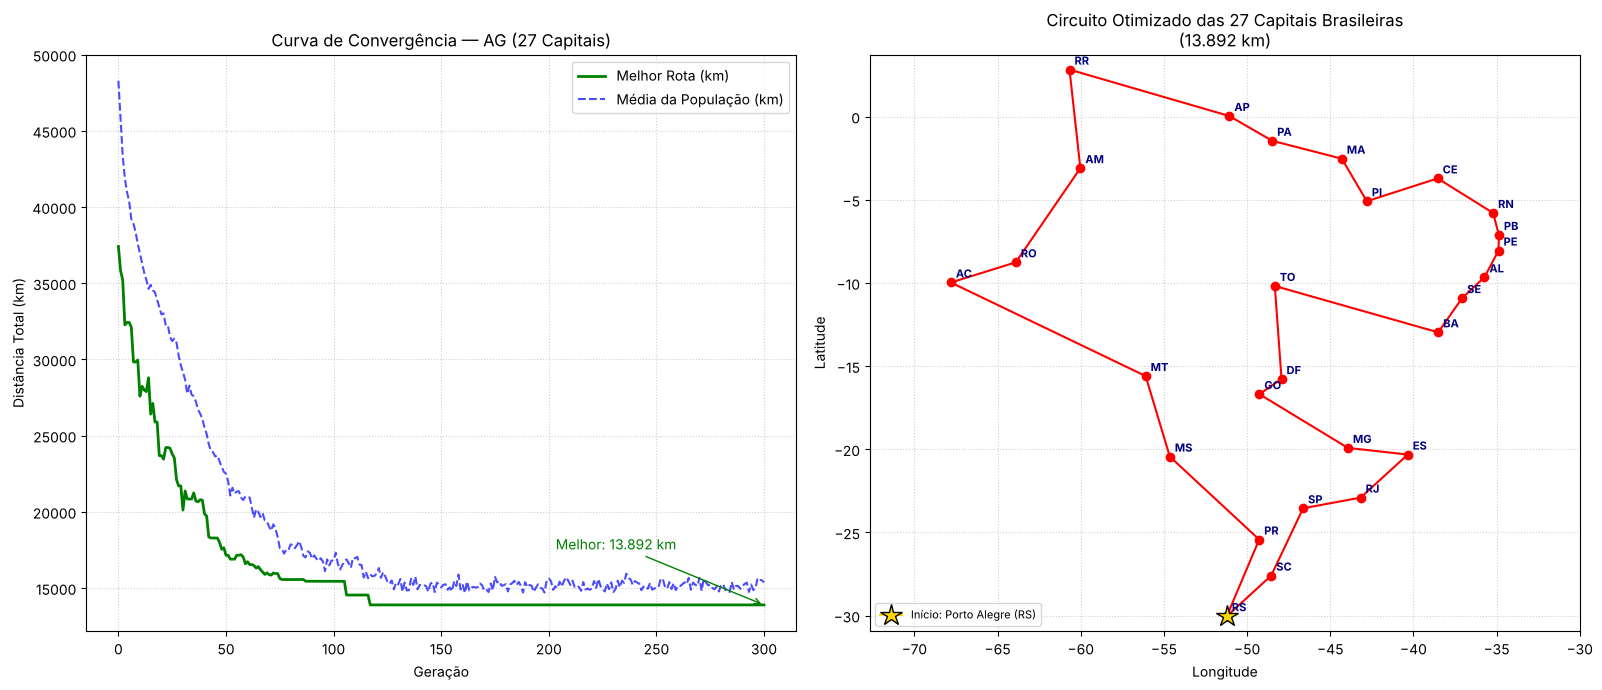

In [10]:
def plotar_resultados(logbook, melhor_rota, melhor_distancia=None, salvar_em=None):
    """
    Dois gráficos lado a lado:
    - Esquerda: Curva de Convergência (Geração vs Distância Mínima e Média)
    - Direita: Longitude vs Latitude das capitais conectadas pela melhor rota.
    """
    if logbook is None:
        print("Execute a função 'executar_ag()' antes de plotar.")
        return

    gen = logbook.select("gen")
    fit_mins = logbook.select("min")
    fit_avgs = logbook.select("avg")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

    # 1. Curva de Convergência
    ax1.plot(gen, fit_mins, label="Melhor Rota (km)", color="green", linewidth=2)
    ax1.plot(gen, fit_avgs, label="Média da População (km)", color="blue", linestyle="--", alpha=0.7)
    ax1.set_title("Curva de Convergência — AG (27 Capitais)")
    ax1.set_xlabel("Geração")
    ax1.set_ylabel("Distância Total (km)")
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend()
    if melhor_distancia is not None:
        ax1.annotate(f"Melhor: {melhor_distancia:,.0f} km".replace(",", "."),
                     xy=(gen[-1], fit_mins[-1]), xytext=(-150, 40),
                     textcoords="offset points", fontsize=10, color="green",
                     arrowprops=dict(arrowstyle="->", color="green"))

    # 2. Plotagem Geográfica (fecha o circuito voltando à primeira cidade)
    rota_fechada = list(melhor_rota) + [melhor_rota[0]]
    lats = [CAPITAIS_BRASIL[NOMES_CIDADES[i]][0] for i in rota_fechada]
    lons = [CAPITAIS_BRASIL[NOMES_CIDADES[i]][1] for i in rota_fechada]

    ax2.plot(lons, lats, 'o-', color="red", markersize=6, linewidth=1.5)
    inicio = NOMES_CIDADES[melhor_rota[0]]
    ax2.plot(CAPITAIS_BRASIL[inicio][1], CAPITAIS_BRASIL[inicio][0], marker="*",
             color="gold", markeredgecolor="black", markersize=16, label=f"Início: {inicio}")
    for i in melhor_rota:
        nome_cid = NOMES_CIDADES[i]
        lat, lon = CAPITAIS_BRASIL[nome_cid]
        sigla = nome_cid.split('(')[1].replace(')', '')
        ax2.text(lon + 0.3, lat + 0.3, sigla, fontsize=8, fontweight="bold", color="navy")

    titulo = "Circuito Otimizado das 27 Capitais Brasileiras"
    if melhor_distancia is not None:
        titulo += f"\n({melhor_distancia:,.0f} km)".replace(",", ".")
    ax2.set_title(titulo)
    ax2.set_xlabel("Longitude")
    ax2.set_ylabel("Latitude")
    ax2.set_aspect("equal", adjustable="datalim")
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(loc="lower left", fontsize=8)

    plt.tight_layout()
    if salvar_em:
        plt.savefig(salvar_em, dpi=130, bbox_inches="tight")
    plt.show()


plotar_resultados(logbook, melhor_rota, melhor_dist)

## Análise complementar — robustez com outras sementes

O AG é estocástico. Para ver se o resultado não depende de uma semente "sortuda", rodamos a mesma configuração com outras sementes e comparamos com a melhor rota de referência obtida por busca local **2-opt** com 200 reinícios aleatórios (usada só como régua de comparação; não faz parte do AG).

In [11]:
import time

def dois_opt(rota):
    rota = rota[:]
    melhorou = True
    while melhorou:
        melhorou = False
        for i in range(1, N_CIDADES - 1):
            for j in range(i + 1, N_CIDADES):
                nova = rota[:i] + rota[i:j + 1][::-1] + rota[j + 1:]
                if avaliar_rota(nova)[0] < avaliar_rota(rota)[0] - 1e-9:
                    rota, melhorou = nova, True
    return rota

random.seed(0)
referencia = min(avaliar_rota(dois_opt(random.sample(range(N_CIDADES), N_CIDADES)))[0] for _ in range(200))
print(f"Referência (2-opt, 200 reinícios): {referencia:,.1f} km\n")

print(f"{'Semente':>8} | {'Distância (km)':>14} | {'Gap p/ referência':>17} | {'Tempo':>6}")
print("-" * 56)
resultados = []
for semente in [42, 1, 7, 123, 2026]:
    t0 = time.time()
    _, _, _, dist = executar_ag(semente=semente, verbose=False)
    resultados.append(dist)
    print(f"{semente:>8} | {dist:>14,.1f} | {100 * (dist / referencia - 1):>16.2f}% | {time.time() - t0:>5.1f}s")
print("-" * 56)
print(f"Média: {np.mean(resultados):,.1f} km  |  Desvio-padrão: {np.std(resultados):,.1f} km")

Referência (2-opt, 200 reinícios): 13,786.7 km

 Semente | Distância (km) | Gap p/ referência |  Tempo
--------------------------------------------------------


      42 |       13,892.0 |             0.76% |   2.4s


       1 |       13,955.2 |             1.22% |   2.3s


       7 |       14,574.4 |             5.71% |   2.2s


     123 |       13,955.2 |             1.22% |   2.2s


    2026 |       14,406.3 |             4.49% |   2.2s
--------------------------------------------------------
Média: 14,156.6 km  |  Desvio-padrão: 278.6 km


## Conclusões

1. **Resultado:** a melhor rota encontrada (semente 42) tem **13.892 km**. Parte de Porto Alegre, sobe pelo Centro-Oeste até a Região Norte, percorre o litoral do Nordeste e volta pelo Sudeste e Sul. O mapa não tem cruzamentos de arestas nem idas e vindas geográficas discrepantes.
2. **Convergência:** a melhor distância caiu de ~37.416 km (geração 0) para 13.892 km, uma redução de ~63%. A estabilização ocorre por volta da geração 117. Depois disso a média da população oscila em torno de 15.000 km: a mutação e o crossover continuam gerando variação, mas sem achar rotas melhores.
3. **Sem elitismo:** o `eaSimple` não preserva automaticamente o melhor indivíduo, então o mínimo por geração pode subir em alguns momentos (ex.: gerações 9, 14 e 22 do log). O `HallOfFame` garante que a melhor rota já vista nunca se perde.
4. **Qualidade:** comparado com a referência por 2-opt (13.787 km), o AG ficou apenas **0,76%** acima com a semente 42, avaliando cerca de 53 mil rotas (200 × ~265 por geração). Isso é uma fração ínfima dos 2 × 10²⁶ circuitos possíveis, em ~2 segundos.
5. **Variabilidade:** entre sementes, o resultado variou de 13.892 a 14.574 km (gap de 0,8% a 5,7%). Isso mostra a natureza estocástica do AG e indica melhorias para os próximos marcos: elitismo, mutação por inversão (2-opt) ou busca local híbrida (algoritmo memético), além da comparação com Colônia de Formigas (ACO) no Marco 2.